Box Size: 35000.00 ckpc/h
Mass of the Halo (M200c): 611.68 x 10^10 M_sun/h
Halo R200: 435.01 ckpc/h

Reading snapshot to generate 2D Context Map...


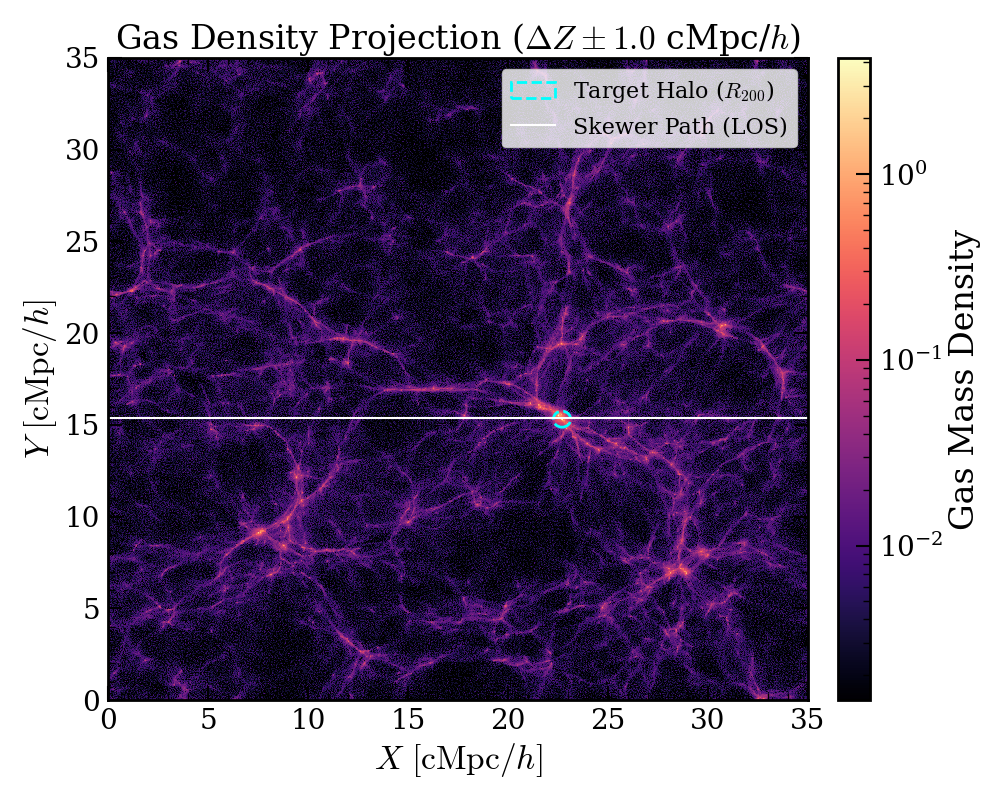


Running fake_spectra extraction (Mode: None)...
Reloading from snapshot (will save to:  ./dummy_none.hdf5  )
1  sightlines. resolution:  1.0001378304253183  z= 3.008131071630377
rank = 0 | Interpolation 9.1 percent done
rank = 0 | Interpolation 18.2 percent done
rank = 0 | Interpolation 27.3 percent done
rank = 0 | Interpolation 36.4 percent done
rank = 0 | Interpolation 45.5 percent done
rank = 0 | Interpolation 54.5 percent done
rank = 0 | Interpolation 63.6 percent done
rank = 0 | Interpolation 72.7 percent done
rank = 0 | Interpolation 81.8 percent done
rank = 0 | Interpolation 90.9 percent done
rank = 0 | Interpolation 9.1 percent done
rank = 0 | Interpolation 18.2 percent done
rank = 0 | Interpolation 27.3 percent done
rank = 0 | Interpolation 36.4 percent done
rank = 0 | Interpolation 45.5 percent done
rank = 0 | Interpolation 54.5 percent done
rank = 0 | Interpolation 63.6 percent done
rank = 0 | Interpolation 72.7 percent done
rank = 0 | Interpolation 81.8 percent done
rank =

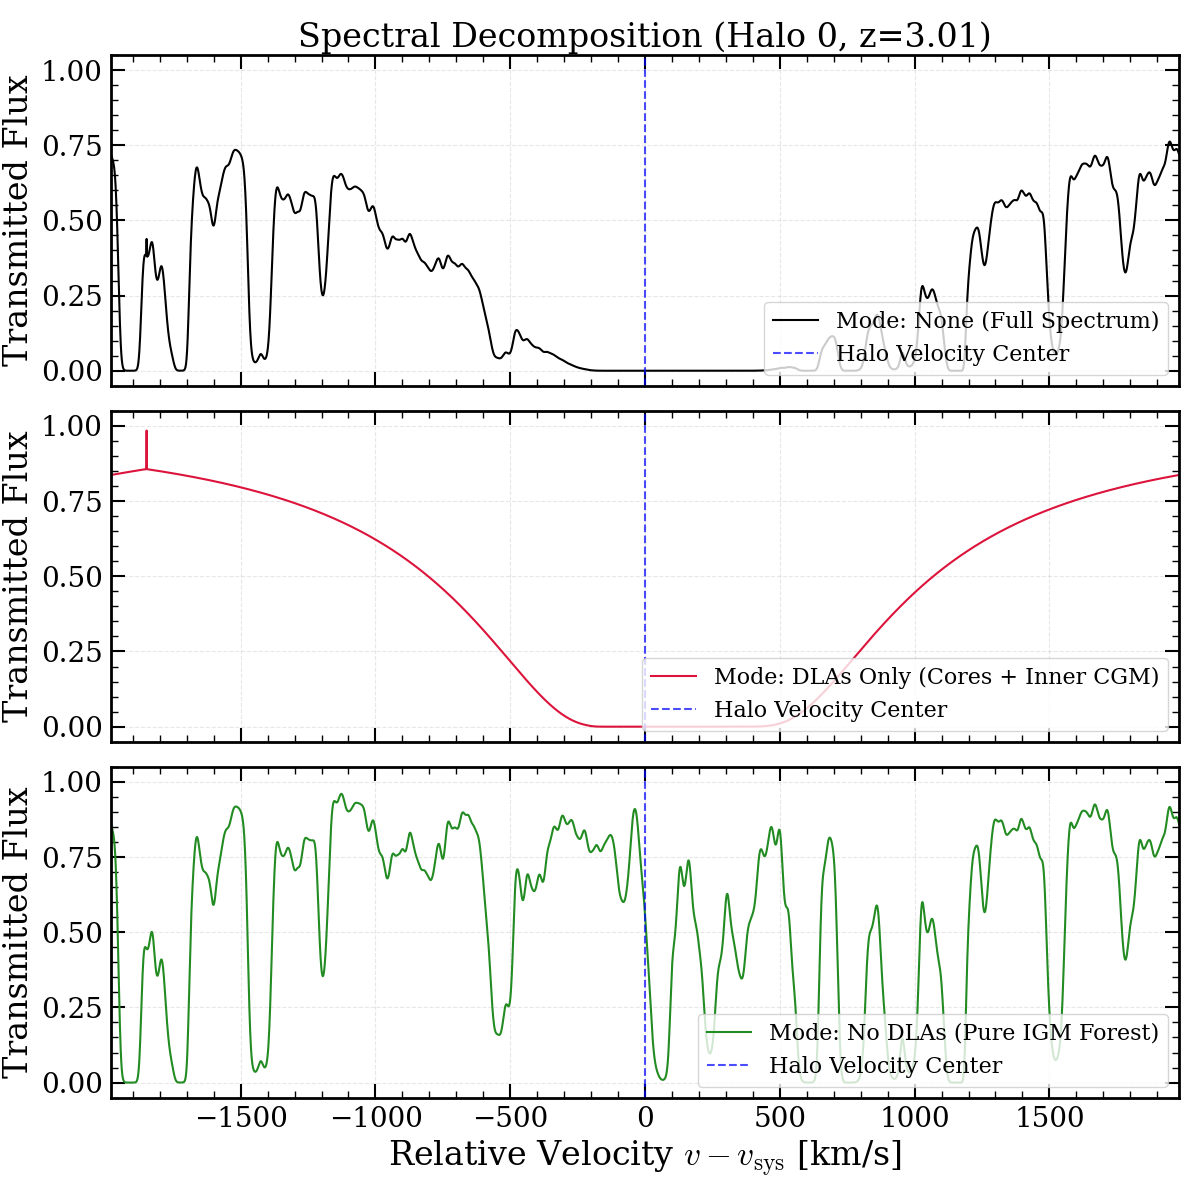

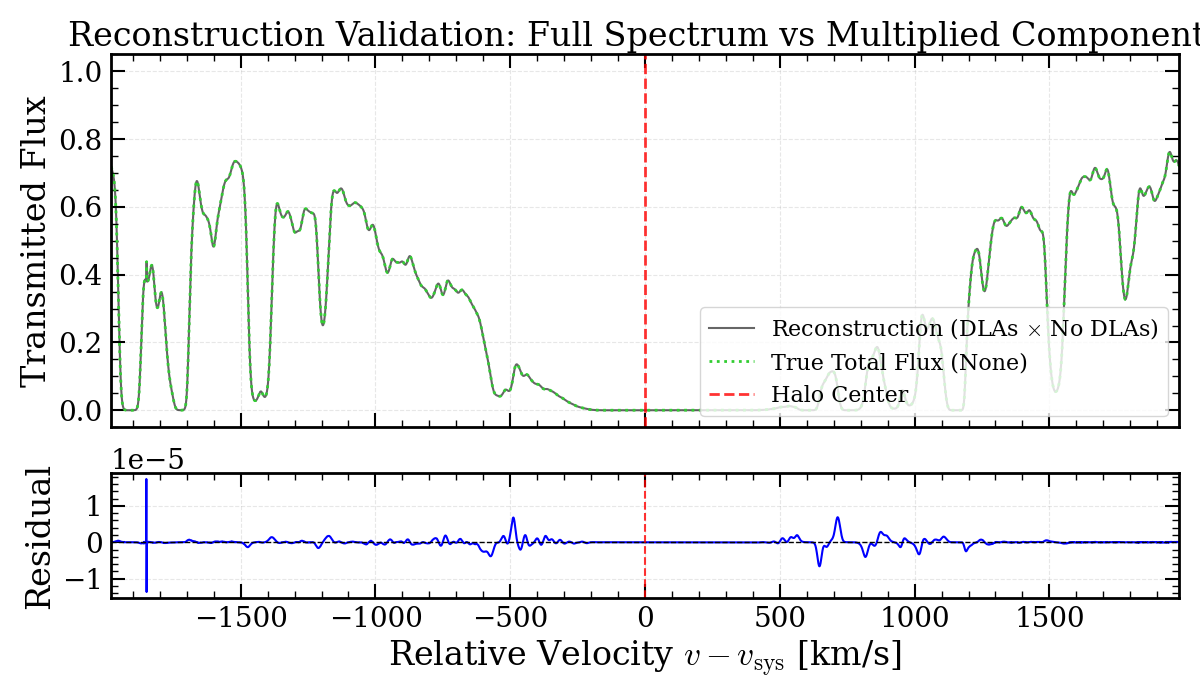

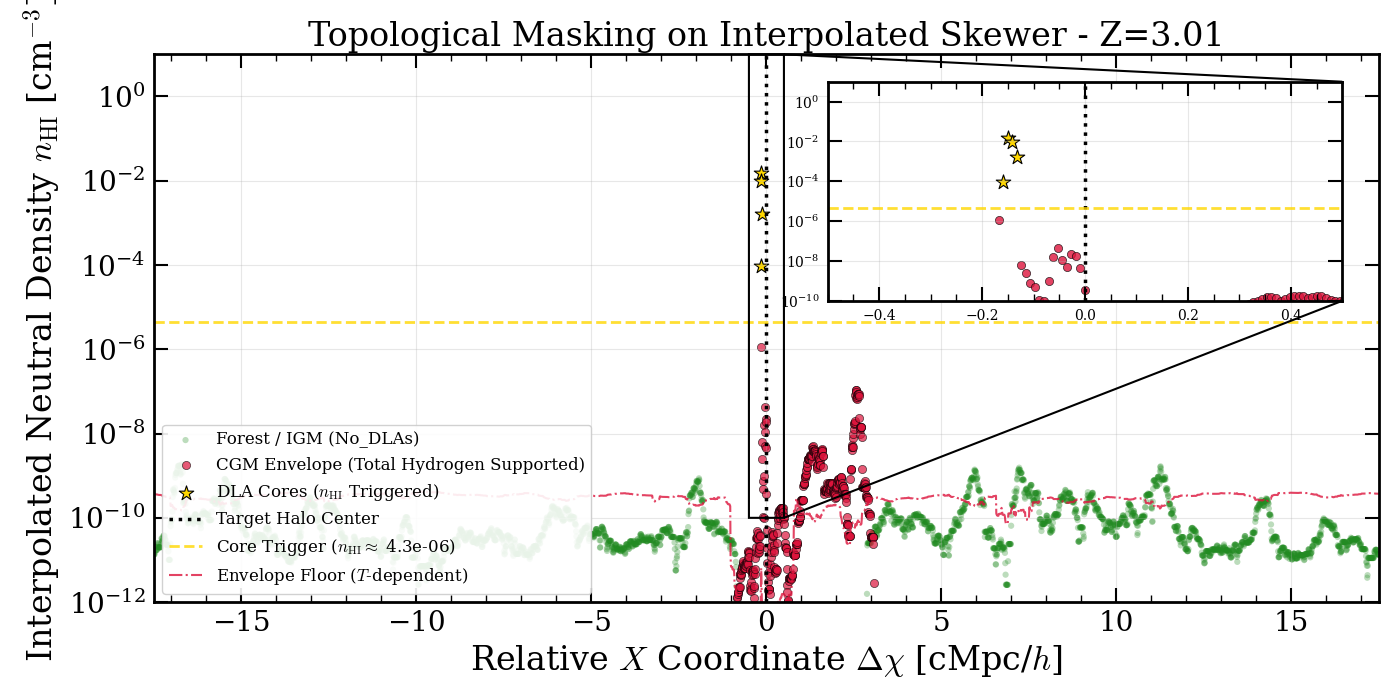

In [1]:
# ==============================================================================
# CELL 0: CONFIGURATION & IMPORTS
# ==============================================================================
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import LogNorm
import h5py
import os

import fake_spectra.spectra as spectra
import fake_spectra.unitsystem as unitsystem

def matplotlib_default_config():
    """Applies a clean, publication-ready style for matplotlib."""
    font = {'family' : 'serif', 'weight' : 'normal', 'size'   : 14}
    rcnew = {
        "mathtext.fontset" : "cm", "text.usetex": False, 'figure.frameon': True,
        'axes.linewidth': 2., "axes.titlesize" : 24, "axes.labelsize" : 24,
        "legend.fontsize" : 16, 'legend.fancybox': True, 'lines.linewidth': 2.5,
        'xtick.alignment': 'center', 'xtick.bottom': True, 'xtick.color': 'black',
        'xtick.direction': 'in', 'xtick.labelbottom': True, 'xtick.labelsize': 20,
        'xtick.major.bottom': True, 'xtick.major.pad': 6.0, 'xtick.major.size': 10.0,
        'xtick.major.width': 1.5, 'xtick.minor.bottom': True, 'xtick.minor.pad': 3.4,
        'xtick.minor.size': 5.0, 'xtick.minor.visible': True, 'xtick.minor.width': 1.0,
        'xtick.top': True, 'ytick.alignment': 'center_baseline', 'ytick.color': 'black',
        'ytick.direction': 'in', 'ytick.labelleft': True, 'ytick.labelsize': 20,
        'ytick.left': True, 'ytick.major.left': True, 'ytick.major.pad': 6.0,
        'ytick.major.size': 10.0, 'ytick.major.width': 1.5, 'ytick.minor.left': True,
        'ytick.minor.pad': 3.4, 'ytick.minor.right': True, 'ytick.minor.size': 5.0,
        'ytick.minor.visible': True, 'ytick.minor.width': 1.0, 'ytick.right': True
    }
    return font, rcnew

%matplotlib widget 
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

# ==============================================================================
# CELL 1: SIMULATION PARAMETERS & SMART HALO SEARCH
# ==============================================================================
base_path = '/home/STORAGE/TNG50-4'
snap_num = 25  
target_halo_id = 0 

def get_halo_info(base_dir, snap_number, halo_id):
    """Fetches Halo position, velocity, mass, and R200c from the subfind catalogs."""
    group_dir = os.path.join(base_dir, f"groups_{snap_number:03d}")
    file0 = os.path.join(group_dir, f"fof_subhalo_tab_{snap_number:03d}.0.hdf5")
    
    with h5py.File(file0, 'r') as f:
        num_files = f['Header'].attrs['NumFiles']
        total_halos = f['Header'].attrs['Ngroups_Total']
        box_size = f['Header'].attrs['BoxSize']
        
    if halo_id >= total_halos:
        raise ValueError(f"Invalid ID {halo_id}. Max is {total_halos - 1}.")
        
    current_id_offset = 0
    for i in range(num_files):
        filepath = os.path.join(group_dir, f"fof_subhalo_tab_{snap_number:03d}.{i}.hdf5")
        with h5py.File(filepath, 'r') as f:
            if 'Group' not in f or 'GroupMass' not in f['Group']: continue
            n_halos = len(f['Group/GroupMass'])
            if halo_id < current_id_offset + n_halos:
                local_index = halo_id - current_id_offset
                return (f['Group/GroupPos'][local_index], f['Group/GroupVel'][local_index], 
                        f['Group/Group_M_Crit200'][local_index], f['Group/Group_R_Crit200'][local_index], box_size)
            current_id_offset += n_halos

halo_pos, halo_vel, halo_mass, halo_r200, box_size = get_halo_info(base_path, snap_num, target_halo_id)

# Define skewer placement (offset from Halo center in Y, hitting exact Z)
shift_kpc = 50 # cKpc/h
y_sk, z_halo = halo_pos[1] + shift_kpc, halo_pos[2]
cofm = np.array([[halo_pos[0], y_sk, z_halo]])

print(f"Box Size: {box_size:.2f} ckpc/h")
print(f"Mass of the Halo (M200c): {halo_mass:.2f} x 10^10 M_sun/h")
print(f"Halo R200: {halo_r200:.2f} ckpc/h")

# Extract cosmology
snap_file_0 = os.path.join(base_path, f'snapdir_{snap_num:03d}', f'snap_{snap_num:03d}.0.hdf5')
with h5py.File(snap_file_0, 'r') as f:
    header = f['Header'].attrs
    hubble = header.get('HubbleParam', 0.6774)
    a_scale = header.get('Time', 1.0)
    z_sim = header.get('Redshift', (1.0/a_scale) - 1.0)
    num_snap_files = header.get('NumFilesPerSnapshot', header.get('NumFiles', 1))

# ==============================================================================
# CELL 2: 2D GAS DENSITY PROJECTION (CONTEXT MAP)
# ==============================================================================
print("\nReading snapshot to generate 2D Context Map...")
slice_half_width = 1000 # ckpc/h for the Z-axis slice
x_gas, y_gas, mass_gas = [], [], []

for i in range(num_snap_files):
    snap_file = os.path.join(base_path, f'snapdir_{snap_num:03d}', f'snap_{snap_num:03d}.{i}.hdf5')
    if not os.path.exists(snap_file): continue
    try:
        with h5py.File(snap_file, 'r') as f:
            if 'PartType0' not in f: continue
            coords = f['PartType0']['Coordinates'][:]
            masses = f['PartType0']['Masses'][:]
            
            # Apply Periodic Boundary Conditions for the Z-slice around the Halo
            dz = np.abs(coords[:, 2] - z_halo)
            dz = np.where(dz > box_size / 2.0, box_size - dz, dz)
            mask = dz <= slice_half_width
            
            if np.sum(mask) > 0:
                x_gas.append(coords[:, 0][mask])
                y_gas.append(coords[:, 1][mask])
                mass_gas.append(masses[mask])
    except Exception:
        pass

# Plotting the Context Map
fig_map, ax_map = plt.subplots(figsize=(10, 8))
ax_map.set_facecolor('black')

# Convert to cMpc/h for cleaner axes
plot_box = box_size / 1000.0
h_map, xedges, yedges, img = ax_map.hist2d(
    np.concatenate(x_gas) / 1000.0, np.concatenate(y_gas) / 1000.0, 
    bins=800, range=[[0, plot_box], [0, plot_box]], 
    weights=np.concatenate(mass_gas), cmap='magma', norm=LogNorm()
)

# Draw Halo R200 and Skewer Path
circle = patches.Circle(
    (halo_pos[0]/1000.0, halo_pos[1]/1000.0), radius=halo_r200/1000.0, 
    linewidth=2.0, edgecolor='cyan', facecolor='none', linestyle='--', 
    label=rf'Target Halo ($R_{{200}}$)'
)
ax_map.add_patch(circle)
ax_map.axhline(y=y_sk/1000.0, color='white', linestyle='-', linewidth=1.5, label='Skewer Path (LOS)')

ax_map.set_xlabel(r'$X \ [\mathrm{cMpc}/h]$')
ax_map.set_ylabel(r'$Y \ [\mathrm{cMpc}/h]$')
ax_map.set_title(rf'Gas Density Projection ($\Delta Z \pm {slice_half_width/1000:.1f}$ cMpc/$h$)')
ax_map.legend(loc='upper right', facecolor='white', framealpha=0.8)
fig_map.colorbar(img, ax=ax_map, fraction=0.046, pad=0.04).set_label(r'Gas Mass Density')
plt.tight_layout()
plt.show()

# ==============================================================================
# CELL 3: FAKE SPECTRA NATIVE EXTRACTION (MODE: NONE)
# ==============================================================================
print("\nRunning fake_spectra extraction (Mode: None)...")
axis = np.array([1], dtype=np.int32)
tng_units = unitsystem.UnitSystem(UnitLength_in_cm=3.085678e21, UnitMass_in_g=1.989e43, UnitVelocity_in_cm_per_s=1e5)

# Standard extraction: Retrieves the full spectrum.
# NOTE: Arepo/TNG uses Voronoi/Tophat naturally, so we let kernel=None resolve it natively.
ss_none = spectra.Spectra(
    snap_num, base_path, cofm=cofm, axis=axis, res=1, 
    savedir=".", savefile="dummy_none.hdf5", reload_file=True, kernel=None,
    units=tng_units, sf_neutral=True, filter_mode="None"
)

flux_fs = np.exp(-ss_none.get_tau("H", 1, 1215)[0, :])
nHI_fs = ss_none.get_density("H", 1)[0, :] 
nH_fs = ss_none.get_density("H", -1)[0, :] 
temp_fs = ss_none.get_temp("H", -1)[0, :] # Required for dynamic plotting

# ------------------------------------------------------------------------------
# KINEMATIC & SPATIAL CENTERING
# ------------------------------------------------------------------------------
print("Centralizing spectrum to Halo Rest Frame & Spatial Center...")
nbins, vmax, c_light, lam_rest = ss_none.nbins, ss_none.vmax, 299792.458, 1215.67   

v_axis = np.arange(nbins) * (vmax / nbins)
v_sys = (halo_pos[0] / box_size) * vmax + (halo_vel[0] * np.sqrt(a_scale))

v_rel_wrapped = (v_axis - v_sys + vmax / 2.0) % vmax - vmax / 2.0
sort_idx_v = np.argsort(v_rel_wrapped)

v_common = np.linspace(-vmax / 2.0, vmax / 2.0, nbins)
flux_centered = np.interp(v_common, v_rel_wrapped[sort_idx_v], flux_fs[sort_idx_v])

chi_rel_wrapped = (np.arange(nbins) * (box_size / nbins) - halo_pos[0] + box_size / 2.0) % box_size - box_size / 2.0
sort_idx_chi = np.argsort(chi_rel_wrapped)
chi_common_plot = np.linspace(-box_size / 2.0, box_size / 2.0, nbins) / 1000.0 # cMpc/h

# Apply physical space centering to densities AND temperature
nHI_centered = np.interp(chi_common_plot * 1000.0, chi_rel_wrapped[sort_idx_chi], nHI_fs[sort_idx_chi])
temp_centered = np.interp(chi_common_plot * 1000.0, chi_rel_wrapped[sort_idx_chi], temp_fs[sort_idx_chi])

# ==============================================================================
# CELL 4: TOPOLOGICAL EXTRACTION (DLAS AND NO-DLAS)
# ==============================================================================
print("\nExtracting DLAs-only spectrum (Hybrid Region Growing active)...")
ss_dlas = spectra.Spectra(
    snap_num, base_path, cofm=cofm, axis=axis, res=1, 
    savedir=".", savefile="dummy_dlas.hdf5", reload_file=True, kernel=None,
    units=tng_units, sf_neutral=True, filter_mode="DLAs", dla_phys_thresh="auto"
)
flux_dlas = np.exp(-ss_dlas.get_tau("H", 1, 1215)[0, :])
nHI_dlas_fs = ss_dlas.get_density("H", 1)[0, :] # Extract specifically the masked DLA density

print("\nExtracting No-DLAs (Forest-only) spectrum...")
ss_nodlas = spectra.Spectra(
    snap_num, base_path, cofm=cofm, axis=axis, res=1, 
    savedir=".", savefile="dummy_nodlas.hdf5", reload_file=True, kernel=None,
    units=tng_units, sf_neutral=True, filter_mode="No_DLAs", dla_phys_thresh="auto"
)
flux_nodlas = np.exp(-ss_nodlas.get_tau("H", 1, 1215)[0, :])
nHI_nodlas_fs = ss_nodlas.get_density("H", 1)[0, :] # Extract specifically the masked Forest density

# Center fluxes using the established common velocity space
flux_dlas_centered = np.interp(v_common, v_rel_wrapped[sort_idx_v], flux_dlas[sort_idx_v])
flux_nodlas_centered = np.interp(v_common, v_rel_wrapped[sort_idx_v], flux_nodlas[sort_idx_v])

# Center masked densities using the established spatial space
nHI_dlas_centered = np.interp(chi_common_plot * 1000.0, chi_rel_wrapped[sort_idx_chi], nHI_dlas_fs[sort_idx_chi])
nHI_nodlas_centered = np.interp(chi_common_plot * 1000.0, chi_rel_wrapped[sort_idx_chi], nHI_nodlas_fs[sort_idx_chi])

# Retrieve Hybrid Extraction Thresholds
core_thresh_nH = ss_dlas.dla_phys_thresh_nH
core_thresh_nHI = ss_dlas.dla_phys_thresh_nHI
envelope_thresh_nH = getattr(ss_dlas, 'dla_envelope_thresh', core_thresh_nH * 1e-2)

print(f"\nTopological Thresholds:")
print(f" -> Neutral Hydrogen Core Trigger (nHI): {core_thresh_nHI:.2e} cm^-3")
print(f" -> Total Hydrogen CGM Envelope (nH): {envelope_thresh_nH:.2e} cm^-3")

# ==============================================================================
# CELL 5: FLUX DECOMPOSITION PLOT
# ==============================================================================
fig_decomp, axes = plt.subplots(3, 1, figsize=(12, 12), sharex=True)

axes[0].plot(v_common, flux_centered, color='black', lw=1.5, label='Mode: None (Full Spectrum)')
axes[0].set_title(f'Spectral Decomposition (Halo {target_halo_id}, z={z_sim:.2f})')

axes[1].plot(v_common, flux_dlas_centered, color='crimson', lw=1.5, label='Mode: DLAs Only (Cores + Inner CGM)')
axes[2].plot(v_common, flux_nodlas_centered, color='forestgreen', lw=1.5, label='Mode: No DLAs (Pure IGM Forest)')
axes[2].set_xlabel(r'Relative Velocity $v - v_{\mathrm{sys}}$ [km/s]')

for ax in axes:
    ax.set_ylabel('Transmitted Flux')
    ax.axvline(0.0, color='blue', linestyle='--', lw=1.5, alpha=0.7, label='Halo Velocity Center')
    ax.set_xlim(-vmax / 2.0, vmax / 2.0)
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

# ==============================================================================
# CELL 6: MULTIPLICATIVE RESIDUAL VALIDATION
# ==============================================================================
flux_multiplication = flux_nodlas_centered * flux_dlas_centered
fig_res, (ax_top, ax_bot) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

ax_top.plot(v_common, flux_multiplication, color='black', lw=1.5, alpha=0.6, label='Reconstruction (DLAs $\\times$ No DLAs)')
ax_top.plot(v_common, flux_centered, linestyle=':', color='limegreen', lw=2, label='True Total Flux (None)')
ax_top.axvline(0.0, color='red', linestyle='--', lw=2, alpha=0.8, label='Halo Center')
ax_top.set_ylabel('Transmitted Flux')
ax_top.set_title('Reconstruction Validation: Full Spectrum vs Multiplied Components')
ax_top.set_ylim(-0.05, 1.05)
ax_top.grid(True, alpha=0.3, linestyle='--')
ax_top.legend(loc='lower right')

residuals = flux_multiplication - flux_centered
ax_bot.plot(v_common, residuals, color='blue', lw=1.5)
ax_bot.axhline(0.0, color='black', linestyle='--', lw=1)
ax_bot.axvline(0.0, color='red', linestyle='--', lw=1.5, alpha=0.8)
ax_bot.set_xlabel(r'Relative Velocity $v - v_{\mathrm{sys}}$ [km/s]')
ax_bot.set_ylabel('Residual')
ax_bot.set_xlim(-vmax / 2.0, vmax / 2.0)
ax_bot.grid(True, alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

# ==============================================================================
# CELL 7: DISCRETE ANATOMY PLOT (NATIVE MASKING HIGHLIGHTS)
# ==============================================================================
# We no longer recreate the masking logic on the pixel grid.
# Instead, we directly plot the exact outputs that fake_spectra generated from the 3D topology.

# Identify which pixels received the masked particles
mask_dla = nHI_dlas_centered > 1e-15
mask_nodla = nHI_nodlas_centered > 1e-15

# Sub-classify the DLA components to isolate the high-density cores
mask_core = (nHI_dlas_centered >= core_thresh_nHI) & mask_dla
mask_cgm_envelope = mask_dla & ~mask_core

fig_anat, ax_anat = plt.subplots(figsize=(14, 7))

ax_anat.scatter(chi_common_plot[mask_nodla], nHI_nodlas_centered[mask_nodla], 
                color='forestgreen', alpha=0.3, edgecolors='none', s=20, label='Forest / IGM (No_DLAs)')

ax_anat.scatter(chi_common_plot[mask_cgm_envelope], nHI_dlas_centered[mask_cgm_envelope], 
                color='crimson', alpha=0.7, edgecolors='black', linewidth=0.5, s=35, label='CGM Envelope (Total Hydrogen Supported)')

ax_anat.scatter(chi_common_plot[mask_core], nHI_dlas_centered[mask_core], 
                color='gold', alpha=1.0, edgecolors='black', linewidth=0.8, s=120, marker='*', label='DLA Cores ($n_{\\rm HI}$ Triggered)')

ax_anat.axvline(0.0, color='black', linestyle=':', lw=2.5, label='Target Halo Center')

# Constant horizontal line for the trigger (since the trigger itself operates natively on nHI)
ax_anat.axhline(core_thresh_nHI, color='gold', linestyle='--', lw=2, alpha=0.8, 
                label=f'Core Trigger ($n_{{\\rm HI}} \\approx$ {core_thresh_nHI:.1e})')

# -----------------------------------------------------------------------------
# EXACT DYNAMIC ENVELOPE CURVE
# -----------------------------------------------------------------------------
# Calculate the exact nHI equivalent of the nH envelope threshold
# using the actual temperature of the gas at each physical point along the skewer.
fHI_env_dynamic = ss_none.gasprop._neutral_fraction(envelope_thresh_nH, temp_centered)
env_thresh_nHI_dynamic = envelope_thresh_nH * fHI_env_dynamic

ax_anat.plot(chi_common_plot, env_thresh_nHI_dynamic, color='crimson', linestyle='-.', lw=1.5, alpha=0.8, 
             label='Envelope Floor ($T$-dependent)')

ax_anat.set_yscale('log')
ax_anat.set_ylim(1e-12, 1e1)
ax_anat.set_xlim(-box_size / 2000.0, box_size / 2000.0)

ax_anat.set_xlabel(r'Relative $X$ Coordinate $\Delta \chi$ [cMpc/$h$]')
ax_anat.set_ylabel(r'Interpolated Neutral Density $n_{\mathrm{HI}}$ [cm$^{-3}$]')
ax_anat.set_title(f'Topological Masking on Interpolated Skewer - Z={z_sim:.2f}')
ax_anat.legend(loc='lower left', framealpha=0.9, fontsize=12, ncol=1) 
ax_anat.grid(True, alpha=0.3)

# ==============================================================================
# INSET: Surgical Zoom on Main Halo
# ==============================================================================
axins = ax_anat.inset_axes([0.55, 0.55, 0.42, 0.40]) 

axins.scatter(chi_common_plot[mask_nodla], nHI_nodlas_centered[mask_nodla], 
              color='forestgreen', alpha=0.4, edgecolors='none', s=15)
axins.scatter(chi_common_plot[mask_cgm_envelope], nHI_dlas_centered[mask_cgm_envelope], 
              color='crimson', alpha=0.8, edgecolors='black', linewidth=0.5, s=35)
axins.scatter(chi_common_plot[mask_core], nHI_dlas_centered[mask_core], 
              color='gold', alpha=1.0, edgecolors='black', linewidth=0.8, s=120, marker='*')

axins.axvline(0.0, color='black', linestyle=':', lw=2.5)
axins.axhline(core_thresh_nHI, color='gold', linestyle='--', lw=2, alpha=0.8)

# Add the dynamic curve to the inset as well
axins.plot(chi_common_plot, env_thresh_nHI_dynamic, color='crimson', linestyle='-.', lw=1.5, alpha=0.8)

x_zoom = 0.5 
axins.set_xlim(-x_zoom, x_zoom)
axins.set_ylim(1e-10, 1e1)
axins.set_yscale('log')

axins.grid(True, alpha=0.3)
axins.tick_params(labelsize=10)

ax_anat.indicate_inset_zoom(axins, edgecolor="black", alpha=1.0, lw=1.5)

plt.tight_layout()
plt.show()